# ⚡ EcoBot — Analista Energetico AI
### *EcoGrid Solutions | Comunità Energetiche Rinnovabili*

---

## Struttura del Notebook

| Sezione | Contenuto |
|---------|----------|
| **1 — Sviluppo Agente** | Setup, dataset, tool, agente, test |
| **2 — App Streamlit** | Web app interattiva con chat e grafici |

**Architettura scelta**: Agente Singolo con paradigma *ReAct* (Reasoning + Acting)  
**Motivazione**: Il problema è ben perimetrato; la complessità risiede nei 7 tool specializzati, non nell'orchestrazione multi-agente.

---

## SEZIONE 1 — Sviluppo dell'Agente EcoBot

In questa sezione costruiamo il cervello di EcoBot passo per passo:
1. Setup ambiente e librerie
2. Generazione dataset sintetico IoT
3. Definizione dei tool (funzioni Python)
4. Configurazione agente LangChain
5. Test con domande reali

### 1.1 — Setup: Installazione Dipendenze e Configurazione

In [ ]:
# --------------------------------------------------------------
# INSTALLAZIONE DIPENDENZE
# Esegui questa cella SOLO la prima volta (oppure da terminale:
#   pip install -r requirements.txt).
# requirements.txt vincola LangChain alla linea 0.3.x: in LangChain 1.x
# AgentExecutor e create_openai_tools_agent non esistono piu'.
# --------------------------------------------------------------
%pip install -q -r requirements.txt

In [ ]:
# --------------------------------------------------------------
# IMPORT E CONFIGURAZIONE INIZIALE
# --------------------------------------------------------------
import os
import json
import re
import warnings
# Sopprime DeprecationWarning PRIMA degli import di LangChain
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")  # Backend non-interattivo: salva PNG senza GUI
import matplotlib.pyplot as plt
from datetime import datetime
from typing import Optional
from dotenv import load_dotenv
from IPython.display import Image, display

# LangChain — Framework per la costruzione di agenti AI
from langchain_openai import ChatOpenAI
from langchain.agents import AgentExecutor, create_openai_tools_agent
from langchain.tools import tool
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
# Approccio moderno LangChain 0.3.x: lista di messaggi invece di ConversationBufferMemory
from langchain_core.messages import HumanMessage, AIMessage

# Caricamento sicuro dell API Key (mai hardcoded nel codice!)
load_dotenv()
OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")

if not OPENAI_API_KEY:
    raise ValueError(
        "OPENAI_API_KEY non trovata. "
        "Crea il file .env con OPENAI_API_KEY=sk-la-tua-chiave"
    )

# Directory per salvare i grafici PNG
CHARTS_DIR = "charts"
os.makedirs(CHARTS_DIR, exist_ok=True)

# Directory dei dataset CSV (generati nella sezione 1.2)
DATA_DIR = "data"
os.makedirs(DATA_DIR, exist_ok=True)
PRODUCTION_CSV = os.path.join(DATA_DIR, "solar_production_raw.csv")
CONSUMPTION_CSV = os.path.join(DATA_DIR, "household_consumption.csv")

print(f"Setup completato - {datetime.now().strftime('%Y-%m-%d %H:%M')}")
print("API Key caricata dal file .env")

### 1.2 — Generazione Dataset Sintetico IoT

Nella realtà, i dati delle CER possono contenere informazioni sensibili (abitudini domestiche, pattern di presenza).  
Usiamo un dataset **sintetico** che simula realisticamente:
- **Produzione solare**: curva sinusoidale (segue il sole) con rumore gaussiano + anomalie IoT simulate
- **Consumi domestici**: consumo base + picco serale (19-21h)

**Anomalie inserite intenzionalmente** per testare il data cleaning:
- Righe 100-105: `kwh_produced = NaN` (sensore rotto)
- Riga 200: `kwh_produced = -5` (errore di calibrazione sensore)

**Riproducibilità**: seed fisso (`42`) e data di fine fissa → ogni esecuzione genera esattamente lo stesso dataset.

In [3]:
# ──────────────────────────────────────────────────────────────
# GENERAZIONE DATASET SINTETICO
# Produce solar_production_raw.csv e household_consumption.csv
# ──────────────────────────────────────────────────────────────
np.random.seed(42)  # Seed per riproducibilita' dei risultati

# Genera 30 giorni di dati orari (720 righe)
# Data di fine FISSA invece di datetime.today(): insieme al seed rende il
# dataset riproducibile. Con datetime.today(), rieseguendo la cella a un'altra
# ora del giorno cambierebbe l'allineamento ora/valori e quindi ogni risultato.
END_TIMESTAMP = '2026-06-05 17:00'
dates = pd.date_range(end=END_TIMESTAMP, periods=24*30, freq='h')

# ── Dataset Produzione Solare ────────────────────────────────────────────────
# Modello fisico: curva sinusoidale centrata sul mezzogiorno + rumore
production = np.maximum(
    0,
    np.sin((dates.hour.to_numpy() - 6) * np.pi / 12) * 5
    + np.random.normal(0, 0.5, len(dates))
)
production[dates.hour < 6] = 0   # Notte: nessuna produzione
production[dates.hour > 20] = 0  # Notte: nessuna produzione

df_prod = pd.DataFrame({'timestamp': dates, 'kwh_produced': production})

# Introduciamo anomalie (simulazione guasti sensori IoT)
df_prod.loc[100:105, 'kwh_produced'] = np.nan  # Sensore rotto (6 ore)
df_prod.loc[200, 'kwh_produced'] = -5          # Errore calibrazione sensore

# ── Dataset Consumi Domestici ────────────────────────────────────────────────
# Consumo base stazionario + picco serale (tipico di una famiglia italiana)
consumption = np.random.normal(1.5, 0.5, len(dates))        # Base: ~1.5 kWh/h
consumption[dates.hour.isin([19, 20, 21])] += 2             # Picco serale: +2 kWh/h

df_cons = pd.DataFrame({'timestamp': dates, 'kwh_consumed': consumption})

# Salvataggio su file CSV
df_prod.to_csv(PRODUCTION_CSV, index=False)
df_cons.to_csv(CONSUMPTION_CSV, index=False)

print('Dataset generati con successo!')
print(f'  solar_production_raw.csv  → {len(df_prod)} righe')
print(f'  household_consumption.csv → {len(df_cons)} righe')
print(f'  Periodo: {dates[0].strftime("%Y-%m-%d")} → {dates[-1].strftime("%Y-%m-%d")}')
print(f'\nAnomalie inserite:')
print(f'  NaN (righe 100-105): {df_prod["kwh_produced"].isna().sum()} valori')
print(f'  Negativi (riga 200): {(df_prod["kwh_produced"] < 0).sum()} valori')
print(f'\nAnteprima produzione solare:')
df_prod.head()

Dataset generati con successo!
  solar_production_raw.csv  → 720 righe
  household_consumption.csv → 720 righe
  Periodo: 2026-05-06 → 2026-06-05

Anomalie inserite:
  NaN (righe 100-105): 6 valori
  Negativi (riga 200): 1 valori

Anteprima produzione solare:


,timestamp,kwh_produced
0,2026-05-06 18:04:01.906729,0.248357
1,2026-05-06 19:04:01.906729,0.000000
2,2026-05-06 20:04:01.906729,0.000000
3,2026-05-06 21:04:01.906729,0.000000
4,2026-05-06 22:04:01.906729,0.000000


### 1.3 — Definizione dei Tool LangChain

I **tool** sono le "mani" dell'agente: funzioni Python che l'LLM può chiamare autonomamente.

Ogni tool è decorato con `@tool` e deve avere:
- Una **docstring** chiara → l'LLM la usa per decidere quando usare il tool
- **Input tipizzati** → LangChain gestisce la conversione automatica
- **Output JSON** → formato strutturato che l'LLM sa interpretare

**Stato globale**: usiamo variabili globali per i DataFrame puliti,
condivise tra tutti i tool senza doverli ricaricare ogni volta.

In [4]:
# ──────────────────────────────────────────────────────────────
# STATO GLOBALE E FUNZIONE INTERNA DI CLEANING
# I DataFrame vengono caricati una volta e riutilizzati da tutti i tool
# ──────────────────────────────────────────────────────────────

# Variabili globali per i DataFrame puliti (condivise tra i tool)
_df_production: Optional[pd.DataFrame] = None
_df_consumption: Optional[pd.DataFrame] = None


def _load_and_clean_data_internal():
    '''
    Funzione INTERNA di caricamento e pulizia dati.
    Non e' un tool LangChain — e' un helper chiamato dagli altri tool.

    Strategia di cleaning:
    1. Valori negativi → NaN (impossibili per un pannello solare)
    2. NaN → interpolazione lineare (ottimale per serie temporali)
    3. NaN residui ai bordi → fill con 0 (notte/assenza dati)
    4. Duplicati → rimossi, ordinamento temporale garantito
    '''
    try:
        df_prod = pd.read_csv(PRODUCTION_CSV, parse_dates=['timestamp'])
        df_cons = pd.read_csv(CONSUMPTION_CSV, parse_dates=['timestamp'])
    except FileNotFoundError as e:
        raise FileNotFoundError(
            f'File CSV non trovato: {e}. Esegui prima la cella di generazione dataset.'
        )

    # ── Cleaning Produzione Solare ────────────────────────────────────────────
    print(f'  Anomalie trovate — NaN: {df_prod["kwh_produced"].isna().sum()}, '
          f'Negativi: {(df_prod["kwh_produced"] < 0).sum()}')

    df_prod.loc[df_prod['kwh_produced'] < 0, 'kwh_produced'] = np.nan
    df_prod['kwh_produced'] = (
        df_prod['kwh_produced']
        .interpolate(method='linear')
        .fillna(0)
    )
    df_prod = (
        df_prod
        .drop_duplicates(subset='timestamp')
        .sort_values('timestamp')
        .reset_index(drop=True)
    )

    # ── Cleaning Consumi ──────────────────────────────────────────────────────
    df_cons.loc[df_cons['kwh_consumed'] < 0, 'kwh_consumed'] = np.nan
    df_cons['kwh_consumed'] = (
        df_cons['kwh_consumed']
        .interpolate(method='linear')
        .fillna(df_cons['kwh_consumed'].mean())
    )
    df_cons = (
        df_cons
        .drop_duplicates(subset='timestamp')
        .sort_values('timestamp')
        .reset_index(drop=True)
    )

    print(f'  Dopo cleaning — NaN residui: {df_prod["kwh_produced"].isna().sum()}')
    return df_prod, df_cons


def get_production_df() -> pd.DataFrame:
    '''Restituisce il DataFrame produzione, caricandolo se necessario (lazy loading).'''
    global _df_production
    if _df_production is None:
        _df_production, _ = _load_and_clean_data_internal()
    return _df_production


def get_consumption_df() -> pd.DataFrame:
    '''Restituisce il DataFrame consumi, caricandolo se necessario (lazy loading).'''
    global _df_consumption
    if _df_consumption is None:
        _, _df_consumption = _load_and_clean_data_internal()
    return _df_consumption


print('Stato globale e helper di cleaning definiti.')

Stato globale e helper di cleaning definiti.


In [5]:
# ──────────────────────────────────────────────────────────────
# DEFINIZIONE DEI 7 TOOL LANGCHAIN
# Ogni @tool e' una funzione che l'LLM puo' chiamare autonomamente.
# La docstring e' cruciale: l'LLM la legge per decidere QUANDO usare il tool.
# ──────────────────────────────────────────────────────────────

# ── Tool 1: Caricamento e verifica qualita' dati ─────────────────────────────
@tool
def load_and_clean_data(dummy: str = '') -> str:
    '''
    Carica i CSV dei sensori IoT e restituisce un report di qualita' dati.
    Gestisce: valori NaN, valori negativi impossibili, timestamp duplicati.
    Usa questo tool SEMPRE come primo passo prima di qualsiasi analisi.
    '''
    global _df_production, _df_consumption
    try:
        print('  [Tool] load_and_clean_data — caricamento dati...')
        _df_production, _df_consumption = _load_and_clean_data_internal()
        report = {
            'status': 'success',
            'produzione': {
                'righe': len(_df_production),
                'periodo': (
                    f'{_df_production["timestamp"].min().strftime("%Y-%m-%d")}'
                    f' -> {_df_production["timestamp"].max().strftime("%Y-%m-%d")}'
                ),
                'null_dopo_cleaning': int(_df_production['kwh_produced'].isna().sum()),
                'min_kwh': round(float(_df_production['kwh_produced'].min()), 3),
                'max_kwh': round(float(_df_production['kwh_produced'].max()), 3),
            },
            'consumi': {
                'righe': len(_df_consumption),
                'null_dopo_cleaning': int(_df_consumption['kwh_consumed'].isna().sum()),
                'min_kwh': round(float(_df_consumption['kwh_consumed'].min()), 3),
                'max_kwh': round(float(_df_consumption['kwh_consumed'].max()), 3),
            }
        }
        return json.dumps(report, ensure_ascii=False, indent=2)
    except Exception as e:
        return json.dumps({'status': 'error', 'message': str(e)})


# ── Tool 2: Statistiche produzione solare ────────────────────────────────────
@tool
def calculate_solar_production(period: str = 'total') -> str:
    '''
    Calcola statistiche della produzione solare dell'azienda locale.
    Parametro period: "total" (tutto), "daily" (giornaliero), "weekly" (settimanale).
    Restituisce kWh, media, picchi e trend.
    '''
    try:
        print(f'  [Tool] calculate_solar_production — period={period}')
        df = get_production_df().copy()
        df['date'] = df['timestamp'].dt.date
        df['week'] = df['timestamp'].dt.isocalendar().week
        df['hour'] = df['timestamp'].dt.hour
        if period == 'daily':
            result = df.groupby('date')['kwh_produced'].sum()
            return json.dumps({
                'period': 'daily',
                'media_giornaliera_kwh': round(float(result.mean()), 2),
                'giorno_migliore': str(result.idxmax()),
                'max_kwh': round(float(result.max()), 2),
                'ultimi_7_giorni': {str(k): round(v, 2) for k, v in result.tail(7).items()}
            }, ensure_ascii=False)
        elif period == 'weekly':
            result = df.groupby('week')['kwh_produced'].sum()
            return json.dumps({
                'period': 'weekly',
                'dati_settimanali': {str(k): round(v, 2) for k, v in result.items()}
            }, ensure_ascii=False)
        else:
            return json.dumps({
                'period': 'total',
                'totale_kwh_prodotti': round(float(df['kwh_produced'].sum()), 2),
                'media_oraria_kwh': round(float(df['kwh_produced'].mean()), 3),
                'ora_picco_produzione': int(df.groupby('hour')['kwh_produced'].mean().idxmax()),
                'giorni_coperti': int(df['timestamp'].dt.date.nunique()),
            }, ensure_ascii=False)
    except Exception as e:
        return json.dumps({'status': 'error', 'message': str(e)})


# ── Tool 3: Statistiche consumi domestici ────────────────────────────────────
@tool
def calculate_consumption(period: str = 'total') -> str:
    '''
    Calcola statistiche dei consumi energetici domestici.
    Parametro period: "total", "daily", "hourly" (media per ora), "weekly".
    Identifica ore di picco e pattern di consumo.
    '''
    try:
        print(f'  [Tool] calculate_consumption — period={period}')
        df = get_consumption_df().copy()
        df['date'] = df['timestamp'].dt.date
        df['hour'] = df['timestamp'].dt.hour
        df['week'] = df['timestamp'].dt.isocalendar().week
        if period == 'daily':
            result = df.groupby('date')['kwh_consumed'].sum()
            return json.dumps({
                'period': 'daily',
                'media_giornaliera_kwh': round(float(result.mean()), 2),
                'ultimi_7_giorni': {str(k): round(v, 2) for k, v in result.tail(7).items()}
            }, ensure_ascii=False)
        elif period == 'hourly':
            result = df.groupby('hour')['kwh_consumed'].mean()
            return json.dumps({
                'period': 'hourly',
                'ore_picco_consumo': result.nlargest(3).index.tolist(),
                'media_per_ora': {str(k): round(v, 3) for k, v in result.items()}
            }, ensure_ascii=False)
        elif period == 'weekly':
            result = df.groupby('week')['kwh_consumed'].sum()
            return json.dumps({
                'period': 'weekly',
                'dati_settimanali': {str(k): round(v, 2) for k, v in result.items()}
            }, ensure_ascii=False)
        else:
            return json.dumps({
                'period': 'total',
                'totale_kwh_consumati': round(float(df['kwh_consumed'].sum()), 2),
                'media_oraria_kwh': round(float(df['kwh_consumed'].mean()), 3),
                'ore_picco_consumo': df.groupby('hour')['kwh_consumed'].mean().nlargest(3).index.tolist(),
                'giorni_coperti': int(df['timestamp'].dt.date.nunique()),
            }, ensure_ascii=False)
    except Exception as e:
        return json.dumps({'status': 'error', 'message': str(e)})


# ── Tool 4: Rilevamento anomalie ─────────────────────────────────────────────
@tool
def detect_anomalies(dummy: str = '') -> str:
    '''
    Analizza i dati grezzi IoT per rilevare anomalie:
    - Valori mancanti NaN (sensore rotto o disconnesso)
    - Valori negativi (errore di calibrazione sensore)
    - Picchi anomali statistici (oltre 3 deviazioni standard)
    - Gap temporali (ore non registrate dal sensore)
    Usa questo tool per rispondere a domande su guasti o qualita' dei dati.
    '''
    try:
        print('  [Tool] detect_anomalies — analisi anomalie dati grezzi...')
        # Legge i dati GREZZI (prima del cleaning) per trovare le anomalie originali
        df_raw = pd.read_csv(PRODUCTION_CSV, parse_dates=['timestamp'])
        nan_count = int(df_raw['kwh_produced'].isna().sum())
        neg_count = int((df_raw['kwh_produced'] < 0).sum())
        # Outlier statistici (3 sigma)
        mean_v = float(df_raw['kwh_produced'].mean())
        std_v = float(df_raw['kwh_produced'].std())
        outliers = df_raw[df_raw['kwh_produced'] > mean_v + 3 * std_v]
        # Gap temporali
        expected_range = pd.date_range(
            df_raw['timestamp'].min(),
            df_raw['timestamp'].max(),
            freq='h'
        )
        gap_count = len(expected_range.difference(df_raw['timestamp']))
        # Dettaglio dei record anomali
        nan_timestamps = [
            str(t) for t in df_raw[df_raw['kwh_produced'].isna()]['timestamp'].head(5).tolist()
        ]
        neg_records = df_raw[df_raw['kwh_produced'] < 0][['timestamp', 'kwh_produced']].head(3).values.tolist()
        quality = 'CRITICA' if (nan_count + neg_count) > 10 else 'ACCETTABILE'
        return json.dumps({
            'anomalie_nei_dati_grezzi': {
                'valori_nan': nan_count,
                'valori_negativi': neg_count,
                'outlier_3sigma': len(outliers),
                'gap_temporali_ore': gap_count
            },
            'nan_timestamps': nan_timestamps,
            'record_negativi': [[str(r[0]), round(float(r[1]), 2)] for r in neg_records],
            'valutazione_qualita': quality,
            'stato_dopo_cleaning': 'Tutti i valori anomali corretti tramite interpolazione lineare.'
        }, ensure_ascii=False, indent=2)
    except Exception as e:
        return json.dumps({'status': 'error', 'message': str(e)})


# ── Tool 5: Confronto produzione vs consumo ───────────────────────────────────
@tool
def compare_production_vs_consumption(period: str = 'daily') -> str:
    '''
    Confronta produzione solare con consumi domestici.
    Calcola surplus (energia in eccesso da cedere/accumulare) o deficit (import dalla rete).
    Calcola il tasso di autosufficienza energetica.
    Parametro period: "daily" o "weekly".
    '''
    try:
        print(f'  [Tool] compare_production_vs_consumption — period={period}')
        df_prod = get_production_df().copy()
        df_cons = get_consumption_df().copy()
        df = pd.merge(df_prod, df_cons, on='timestamp', how='inner')
        df['surplus'] = df['kwh_produced'] - df['kwh_consumed']
        df['date'] = df['timestamp'].dt.date
        df['week'] = df['timestamp'].dt.isocalendar().week
        total_prod = round(float(df['kwh_produced'].sum()), 2)
        total_cons = round(float(df['kwh_consumed'].sum()), 2)
        total_surplus = round(total_prod - total_cons, 2)
        self_suff = round(min(total_prod, total_cons) / total_cons * 100, 1)
        daily_balance = df.groupby('date')['surplus'].sum()
        return json.dumps({
            'totale_prodotto_kwh': total_prod,
            'totale_consumato_kwh': total_cons,
            'surplus_totale_kwh': total_surplus,
            'autosufficienza_pct': self_suff,
            'bilancio': 'SURPLUS ENERGETICO' if total_surplus > 0 else 'DEFICIT ENERGETICO',
            'giorni_surplus': int((daily_balance > 0).sum()),
            'giorni_deficit': int((daily_balance < 0).sum()),
            'valore_surplus_euro': round(max(0, total_surplus) * 0.25, 2)
        }, ensure_ascii=False, indent=2)
    except Exception as e:
        return json.dumps({'status': 'error', 'message': str(e)})


# ── Tool 6: Generazione grafici ───────────────────────────────────────────────
@tool
def plot_energy_chart(chart_type: str = 'daily_comparison') -> str:
    '''
    Genera e salva un grafico energetico come file PNG.
    Tipi disponibili:
    - "daily_comparison": produzione vs consumo (ultimi 14 giorni)
    - "hourly_pattern": profilo orario medio con aree surplus/deficit colorate
    - "weekly_surplus": surplus/deficit per settimana (blu=surplus, arancio=deficit)
    - "production_timeseries": serie temporale completa produzione solare
    Restituisce il filepath del file PNG salvato.
    '''
    try:
        print(f'  [Tool] plot_energy_chart — type={chart_type}')
        df_prod = get_production_df().copy()
        df_cons = get_consumption_df().copy()
        df = pd.merge(df_prod, df_cons, on='timestamp', how='inner')
        df['date'] = df['timestamp'].dt.date
        df['hour'] = df['timestamp'].dt.hour
        df['week'] = df['timestamp'].dt.isocalendar().week
        df['surplus'] = df['kwh_produced'] - df['kwh_consumed']
        plt.style.use('seaborn-v0_8-darkgrid')
        colors = {'prod': '#2ecc71', 'cons': '#e74c3c', 'surplus': '#3498db', 'deficit': '#e67e22'}
        fig, ax = plt.subplots(figsize=(12, 6))
        if chart_type == 'daily_comparison':
            daily = df.groupby('date').agg(
                kwh_produced=('kwh_produced', 'sum'),
                kwh_consumed=('kwh_consumed', 'sum')
            ).tail(14)
            x = range(len(daily))
            w = 0.38
            ax.bar([i - w/2 for i in x], daily['kwh_produced'], w,
                   label='Produzione Solare', color=colors['prod'], alpha=0.87)
            ax.bar([i + w/2 for i in x], daily['kwh_consumed'], w,
                   label='Consumo Domestico', color=colors['cons'], alpha=0.87)
            ax.set_xticks(list(x))
            ax.set_xticklabels([str(d) for d in daily.index], rotation=45, ha='right', fontsize=8)
            ax.set_title('Produzione Solare vs Consumo Domestico — Ultimi 14 Giorni',
                         fontsize=14, fontweight='bold', pad=15)
            ax.set_ylabel('Energia (kWh)', fontsize=11)
            ax.legend(fontsize=10)
            filename = 'daily_comparison.png'
        elif chart_type == 'hourly_pattern':
            hourly = df.groupby('hour').agg(
                prod=('kwh_produced', 'mean'),
                cons=('kwh_consumed', 'mean')
            )
            ax.plot(hourly.index, hourly['prod'], 'o-',
                    color=colors['prod'], lw=2.5, ms=6, label='Produzione Media')
            ax.plot(hourly.index, hourly['cons'], 's-',
                    color=colors['cons'], lw=2.5, ms=6, label='Consumo Medio')
            ax.fill_between(hourly.index, hourly['prod'], hourly['cons'],
                            where=hourly['prod'] >= hourly['cons'],
                            alpha=0.2, color=colors['prod'], label='Surplus')
            ax.fill_between(hourly.index, hourly['prod'], hourly['cons'],
                            where=hourly['prod'] < hourly['cons'],
                            alpha=0.2, color=colors['cons'], label='Deficit')
            ax.set_xticks(range(24))
            ax.set_xticklabels([f'{h}:00' for h in range(24)], rotation=45, ha='right', fontsize=7)
            ax.set_title('Profilo Orario Medio — Produzione vs Consumo',
                         fontsize=14, fontweight='bold', pad=15)
            ax.set_xlabel('Ora del Giorno', fontsize=11)
            ax.set_ylabel('kWh medi', fontsize=11)
            ax.legend(fontsize=10)
            filename = 'hourly_pattern.png'
        elif chart_type == 'weekly_surplus':
            weekly = df.groupby('week')['surplus'].sum()
            bar_colors = [colors['surplus'] if s >= 0 else colors['deficit'] for s in weekly.values]
            ax.bar(weekly.index.astype(str), weekly.values,
                   color=bar_colors, alpha=0.87, edgecolor='white', linewidth=0.5)
            ax.axhline(0, color='black', lw=1.5, ls='--', alpha=0.7)
            ax.set_title('Surplus / Deficit Energetico Settimanale',
                         fontsize=14, fontweight='bold', pad=15)
            ax.set_xlabel('Settimana', fontsize=11)
            ax.set_ylabel('kWh  |  Blu=Surplus  Arancio=Deficit', fontsize=10)
            filename = 'weekly_surplus.png'
        else:  # production_timeseries
            daily_p = df.groupby('date')['kwh_produced'].sum()
            x_vals = range(len(daily_p))
            ax.plot(x_vals, daily_p.values, color=colors['prod'], lw=1.8, alpha=0.9)
            ax.fill_between(x_vals, daily_p.values, alpha=0.25, color=colors['prod'])
            step = max(1, len(daily_p) // 10)
            ax.set_xticks(list(x_vals)[::step])
            ax.set_xticklabels(
                [str(d) for d in list(daily_p.index)[::step]],
                rotation=45, ha='right', fontsize=8
            )
            ax.set_title('Serie Temporale Produzione Solare',
                         fontsize=14, fontweight='bold', pad=15)
            ax.set_ylabel('kWh Prodotti', fontsize=11)
            filename = 'production_timeseries.png'
        plt.tight_layout()
        filepath = os.path.join(CHARTS_DIR, filename)
        plt.savefig(filepath, dpi=150, bbox_inches='tight')
        plt.close()
        print(f'  Grafico salvato: {filepath}')
        return json.dumps({
            'status': 'success',
            'chart_type': chart_type,
            'filepath': filepath,
            'message': f'Grafico salvato in: {filepath}'
        }, ensure_ascii=False)
    except Exception as e:
        plt.close()
        return json.dumps({'status': 'error', 'message': str(e)})


# ── Tool 7: Consigli energetici personalizzati ────────────────────────────────
@tool
def get_energy_advice(focus: str = 'general') -> str:
    '''
    Genera consigli pratici personalizzati sull'ottimizzazione energetica.
    Parametro focus:
    - "general": panoramica e consigli generali basati sui dati
    - "peak_shifting": come spostare i consumi nelle ore di surplus solare
    - "storage": valutazione acquisto batteria di accumulo
    - "savings": stima del risparmio economico in bolletta
    '''
    try:
        print(f'  [Tool] get_energy_advice — focus={focus}')
        df_prod = get_production_df().copy()
        df_cons = get_consumption_df().copy()
        df = pd.merge(df_prod, df_cons, on='timestamp', how='inner')
        df['hour'] = df['timestamp'].dt.hour
        df['surplus'] = df['kwh_produced'] - df['kwh_consumed']
        hourly = df.groupby('hour').agg(
            avg_prod=('kwh_produced', 'mean'),
            avg_cons=('kwh_consumed', 'mean'),
            avg_surplus=('surplus', 'mean')
        )
        surplus_hours = sorted(hourly[hourly['avg_surplus'] > 0].index.tolist())
        peak_cons_hours = hourly['avg_cons'].nlargest(3).index.tolist()
        total_surplus = float(df['surplus'].sum())
        total_cons = float(df_cons['kwh_consumed'].sum())
        total_prod = float(df_prod['kwh_produced'].sum())
        self_suff = round(min(total_prod, total_cons) / total_cons * 100, 1)
        tariff = 0.25
        surplus_value = round(max(0, total_surplus) * tariff, 2)
        monthly_savings = round(total_cons * tariff * self_suff / 100, 2)
        advice_map = {
            'general': [
                f'Autosufficienza attuale: {self_suff}% del fabbisogno coperto dal solare',
                f'Ore ottimali per elettrodomestici: {surplus_hours[:5]}',
                f'Picchi consumo rilevati alle ore {peak_cons_hours}: redistribuisci i carichi',
                f'Surplus totale disponibile: {round(max(0, total_surplus), 1)} kWh',
                'Considera una batteria di accumulo per usare il surplus di notte'
            ],
            'peak_shifting': [
                f'Programma lavatrice/lavastoviglie nelle ore {surplus_hours[:3]}',
                f'Evita i picchi nelle ore {peak_cons_hours}',
                'Fascia 10:00-15:00 ideale per elettrodomestici ad alta potenza',
                'Usa le funzioni di programmazione oraria degli elettrodomestici smart',
                'Carica il boiler durante le ore di surplus solare'
            ],
            'storage': [
                f'Surplus mensile: {round(max(0, total_surplus), 1)} kWh. Batteria consigliata: 5-10 kWh',
                f'Valore economico del surplus: circa euro {surplus_value} al mese',
                f'Con accumulo potresti coprire il picco serale ({peak_cons_hours}) con energia solare',
                'ROI stimato per sistema accumulo in CER: 5-7 anni',
                'Il surplus in eccesso puo essere ceduto ad altri utenti della CER'
            ],
            'savings': [
                f'Consumo totale periodo: {round(total_cons, 1)} kWh',
                f'Bolletta stimata senza solare: circa euro {round(total_cons * tariff, 2)}',
                f'Risparmio stimato CER: circa euro {monthly_savings} ({self_suff}% autosufficienza)',
                f'Potenziale: spostando carichi nelle ore {surplus_hours[:3]} puoi arrivare al {min(100, self_suff + 10):.0f}%'
            ]
        }
        return json.dumps({
            'focus': focus,
            'autosufficienza_attuale': f'{self_suff}%',
            'ore_surplus_solare': surplus_hours,
            'ore_picco_consumo': peak_cons_hours,
            'risparmio_stimato_euro': monthly_savings,
            'consigli': advice_map.get(focus, advice_map['general'])
        }, ensure_ascii=False, indent=2)
    except Exception as e:
        return json.dumps({'status': 'error', 'message': str(e)})


# Lista di tutti i tool disponibili per l'agente
TOOLS = [
    load_and_clean_data,
    calculate_solar_production,
    calculate_consumption,
    detect_anomalies,
    compare_production_vs_consumption,
    plot_energy_chart,
    get_energy_advice,
]

print(f'Definiti {len(TOOLS)} tool LangChain:')
for t in TOOLS:
    print(f'  - {t.name}')

Definiti 7 tool LangChain:
  - load_and_clean_data
  - calculate_solar_production
  - calculate_consumption
  - detect_anomalies
  - compare_production_vs_consumption
  - plot_energy_chart
  - get_energy_advice


### 1.4 — Configurazione dell'Agente LangChain

**Perché `create_openai_tools_agent` e non ReAct classico?**

- **ReAct** (Reasoning + Acting): l'LLM genera testo libero nel formato `Thought/Action/Observation`. Funziona con qualsiasi modello ma è fragile al formato.
- **OpenAI Tools Agent**: sfrutta il **function calling nativo** di GPT-4o. L'LLM restituisce JSON strutturato per invocare i tool → più affidabile, meno errori di parsing.

**System Prompt Engineering**:  
Il system prompt è la parte più critica: definisce il *personaggio*, il *metodo di ragionamento* (chain-of-thought) e le *regole operative* dell'agente.

In [6]:
# --------------------------------------------------------------
# SYSTEM PROMPT - Il prompt di sistema e' il cuore del prompt engineering.
# Definisce: identita', metodo di ragionamento, regole operative, stile.
# --------------------------------------------------------------

SYSTEM_PROMPT = """
Sei EcoBot, l'analista energetico virtuale di EcoGrid Solutions,
una startup specializzata in comunita' energetiche rinnovabili (CER).

Il tuo compito e' aiutare le famiglie a capire i dati energetici,
ottimizzare i consumi e risparmiare in bolletta, sfruttando l'energia solare.

== METODO DI RAGIONAMENTO (Chain-of-Thought) ==
Prima di rispondere, segui SEMPRE questi passi:
1. COMPRENDI la domanda: dati grezzi, analisi, visualizzazione o consiglio?
2. IDENTIFICA i tool: quali uso? Usa sempre load_and_clean_data come primo tool
3. ESEGUI l'analisi: chiama i tool nell'ordine corretto
4. INTERPRETA: cosa significano i numeri per questa famiglia?
5. RISPONDI: chiaramente, con dati precisi + almeno 1 consiglio pratico

== REGOLE OPERATIVE ==
- Usa SEMPRE load_and_clean_data come primo passo se i dati non sono stati verificati
- Quando generi un grafico, indica SEMPRE il filepath esatto restituito dal tool
- Esprimi l'energia in kWh e spiega cosa significano i valori
- Segnala proattivamente anomalie o inefficienze
- Concludi SEMPRE con almeno un consiglio pratico personalizzato

== STILE ==
- Usa emoji per leggibilita': energia, casa, solare, risparmio, batteria
- Parla come un consulente amico: professionale ma accessibile
- Evita il gergo tecnico; se lo usi, spiegalo
- Sii utile anche per chi non ha competenze tecniche

Obiettivo finale: aiutare ogni famiglia a ridurre la bolletta e vivere in modo piu' sostenibile!
"""

# -- Prompt Template LangChain --------------------------------------------
# MessagesPlaceholder inietta la storia della conversazione (chat_history)
# e gli step intermedi dell'agente (agent_scratchpad).
prompt = ChatPromptTemplate.from_messages([
    ("system", SYSTEM_PROMPT),
    MessagesPlaceholder(variable_name="chat_history"),
    ("human", "{input}"),
    MessagesPlaceholder(variable_name="agent_scratchpad"),
])

# -- LLM: GPT-4o con bassa temperatura ------------------------------------
# temperature=0.3 -> risposte piu' deterministiche e precise per analisi dati
llm = ChatOpenAI(model="gpt-4o", temperature=0.3, api_key=OPENAI_API_KEY)

# -- Costruzione Agente ---------------------------------------------------
agent = create_openai_tools_agent(llm, TOOLS, prompt)

# -- AgentExecutor: il loop di esecuzione ---------------------------------
# handle_parsing_errors=True  -> se l'LLM produce output malformato, riprova
# max_iterations=10           -> previene loop infiniti (sicurezza)
# return_intermediate_steps   -> espone le chiamate ai tool (utile per i grafici)
agent_executor = AgentExecutor(
    agent=agent,
    tools=TOOLS,
    verbose=True,
    handle_parsing_errors=True,
    max_iterations=10,
    max_execution_time=120,
    return_intermediate_steps=True,
)

# -- Memoria conversazionale (approccio moderno LangChain 0.3.x) ----------
# Una semplice lista di HumanMessage/AIMessage: niente ConversationBufferMemory.
chat_history = []

print("Agente EcoBot configurato!")
print(f"  LLM: gpt-4o | Temperature: 0.3")
print(f"  Tool disponibili: {[t.name for t in TOOLS]}")
print(f"  Memoria: lista chat_history ({len(chat_history)} messaggi)")

Agente EcoBot configurato!
  LLM: gpt-4o | Temperature: 0.3
  Tool disponibili: ['load_and_clean_data', 'calculate_solar_production', 'calculate_consumption', 'detect_anomalies', 'compare_production_vs_consumption', 'plot_energy_chart', 'get_energy_advice']
  Memoria: lista chat_history (0 messaggi)


In [7]:
# --------------------------------------------------------------
# FUNZIONE PRINCIPALE: ask_ecobot()
# Interfaccia unificata per interagire con l'agente dal notebook.
# Gestisce memoria, errori e visualizzazione robusta dei grafici.
# --------------------------------------------------------------
from IPython.display import Image, display
import re


def _extract_chart_path(response: dict):
    """
    Estrae il path del grafico in modo ROBUSTO leggendo il JSON realmente
    restituito dal tool plot_energy_chart tramite gli intermediate_steps,
    invece di affidarsi al fatto che l'LLM ripeta la stringa nel testo.
    """
    for action, observation in response.get("intermediate_steps", []):
        if action.tool == "plot_energy_chart":
            try:
                result = json.loads(observation)
                candidate = result.get("filepath")
                if candidate and os.path.exists(candidate):
                    return candidate.replace("\\", "/")
            except (json.JSONDecodeError, TypeError):
                pass
    return None


def ask_ecobot(question: str) -> str:
    """
    Funzione principale per interagire con EcoBot nel notebook.

    Args:
        question: la domanda in linguaggio naturale.

    Returns:
        La risposta testuale dell'agente.

    Side effects:
        - Aggiorna la memoria conversazionale (chat_history).
        - Mostra inline i grafici generati (se presenti).
    """
    print("=" * 65)
    print("UTENTE:", question)
    print("=" * 65)

    try:
        # Invoca l'agente: qui avviene il reasoning loop (Thought -> Action -> Observation)
        response = agent_executor.invoke({
            "input": question,
            "chat_history": chat_history,
        })
        answer = response["output"]

        # Aggiorna la memoria conversazionale
        chat_history.append(HumanMessage(content=question))
        chat_history.append(AIMessage(content=answer))

        # Estrazione robusta del grafico dagli intermediate_steps
        chart_path = _extract_chart_path(response)
        if chart_path:
            print("\n[Grafico generato:", chart_path, "]")
            display(Image(filename=chart_path, width=800))

        print("\nECOBOT:")
        print(answer)
        return answer

    except Exception as e:
        # Recovery automatico: risposta semplificata senza tool
        print("\n[ERRORE]", e, "- Tentativo di recovery...")
        try:
            fallback = llm.invoke([
                ("system", "Sei un consulente energetico. Rispondi brevemente."),
                ("human", question),
            ])
            return fallback.content
        except Exception as e2:
            return "Impossibile elaborare la richiesta: " + str(e2)


print("Funzione ask_ecobot() pronta.")

Funzione ask_ecobot() pronta.


### 1.5 — Test dell'Agente con Domande Reali

Ora testiamo EcoBot con domande realistiche di un cliente EcoGrid.

Osserva il **chain-of-thought** nell'output `verbose=True`:
- L'agente ragiona su quale tool usare
- Chiama il tool e riceve il risultato
- Interpreta il risultato e formula la risposta

**Nota sull'output**: Il formato `[Agent] ...` e `[Tool] ...` è il reasoning loop visibile.

In [8]:
# ── TEST 1: Rilevamento guasti sensori ─────────────────────────────────────────
# Domanda tipica del customer care: il cliente nota dati mancanti sulla dashboard
response1 = ask_ecobot('C\'e\' stato un guasto ai sensori? Voglio capire la qualita\' dei miei dati.')

UTENTE: C'e' stato un guasto ai sensori? Voglio capire la qualita' dei miei dati.


> Entering new AgentExecutor chain...

Invoking: `load_and_clean_data` with `{'dummy': ''}`
responded: Per verificare la qualità dei tuoi dati e identificare eventuali guasti ai sensori, inizierò caricando e pulendo i dati. Questo ci permetterà di rilevare eventuali anomalie come valori mancanti, valori negativi, picchi anomali e gap temporali. Procedo subito!

  [Tool] load_and_clean_data — caricamento dati...
  Anomalie trovate — NaN: 6, Negativi: 1
  Dopo cleaning — NaN residui: 0
{
  "status": "success",
  "produzione": {
    "righe": 720,
    "periodo": "2026-05-06 -> 2026-06-05",
    "null_dopo_cleaning": 0,
    "min_kwh": 0.0,
    "max_kwh": 6.756
  },
  "consumi": {
    "righe": 720,
    "null_dopo_cleaning": 0,
    "min_kwh": 0.052,
    "max_kwh": 4.538
  }
}
Invoking: `detect_anomalies` with `{'dummy': ''}`


  [Tool] detect_anomalies — analisi anomalie dati grezzi...
{
  "anomalie_nei_dati_gr

In [9]:
# ── TEST 2: Analisi produzione totale ─────────────────────────────────────────
response2 = ask_ecobot('Qual e\' la produzione solare totale del periodo e qual e\' il rendimento medio giornaliero?')

UTENTE: Qual e' la produzione solare totale del periodo e qual e' il rendimento medio giornaliero?


> Entering new AgentExecutor chain...

Invoking: `calculate_solar_production` with `{'period': 'total'}`


  [Tool] calculate_solar_production — period=total
{"period": "total", "totale_kwh_prodotti": 1145.31, "media_oraria_kwh": 1.591, "ora_picco_produzione": 12, "giorni_coperti": 31}🌞 **Produzione Solare Totale**
- **Totale Energia Prodotta:** 1145.31 kWh
- **Rendimento Medio Giornaliero:** Circa 36.95 kWh al giorno
- **Produzione Media Oraria:** 1.591 kWh
- **Ora di Picco della Produzione:** Intorno alle 12:00

### 📈 Interpretazione
La tua produzione solare è abbastanza buona, con un picco di produzione a mezzogiorno, il che è tipico poiché il sole è al suo punto più alto. Con una media di circa 37 kWh al giorno, stai sfruttando bene il tuo impianto solare.

### 🔋 Consiglio Pratico
- **Ottimizza i Consumi:** Cerca di concentrare i tuoi consumi energetici più elevati intorno a mezzogi

UTENTE: In quali ore della giornata consumo piu' energia? Genera un grafico del profilo orario.


> Entering new AgentExecutor chain...

Invoking: `calculate_consumption` with `{'period': 'hourly'}`


  [Tool] calculate_consumption — period=hourly
{"period": "hourly", "ore_picco_consumo": [21, 20, 19], "media_per_ora": {"0": 1.651, "1": 1.339, "2": 1.418, "3": 1.509, "4": 1.475, "5": 1.533, "6": 1.667, "7": 1.495, "8": 1.509, "9": 1.632, "10": 1.633, "11": 1.468, "12": 1.523, "13": 1.637, "14": 1.599, "15": 1.421, "16": 1.634, "17": 1.504, "18": 1.549, "19": 3.458, "20": 3.556, "21": 3.706, "22": 1.504, "23": 1.657}}
Invoking: `plot_energy_chart` with `{'chart_type': 'hourly_pattern'}`


  [Tool] plot_energy_chart — type=hourly_pattern
  Grafico salvato: charts\hourly_pattern.png
{"status": "success", "chart_type": "hourly_pattern", "filepath": "charts\\hourly_pattern.png", "message": "Grafico salvato in: charts\\hourly_pattern.png"}🔍 **Analisi dei Consumi Energetici Orari**
- **Ore di

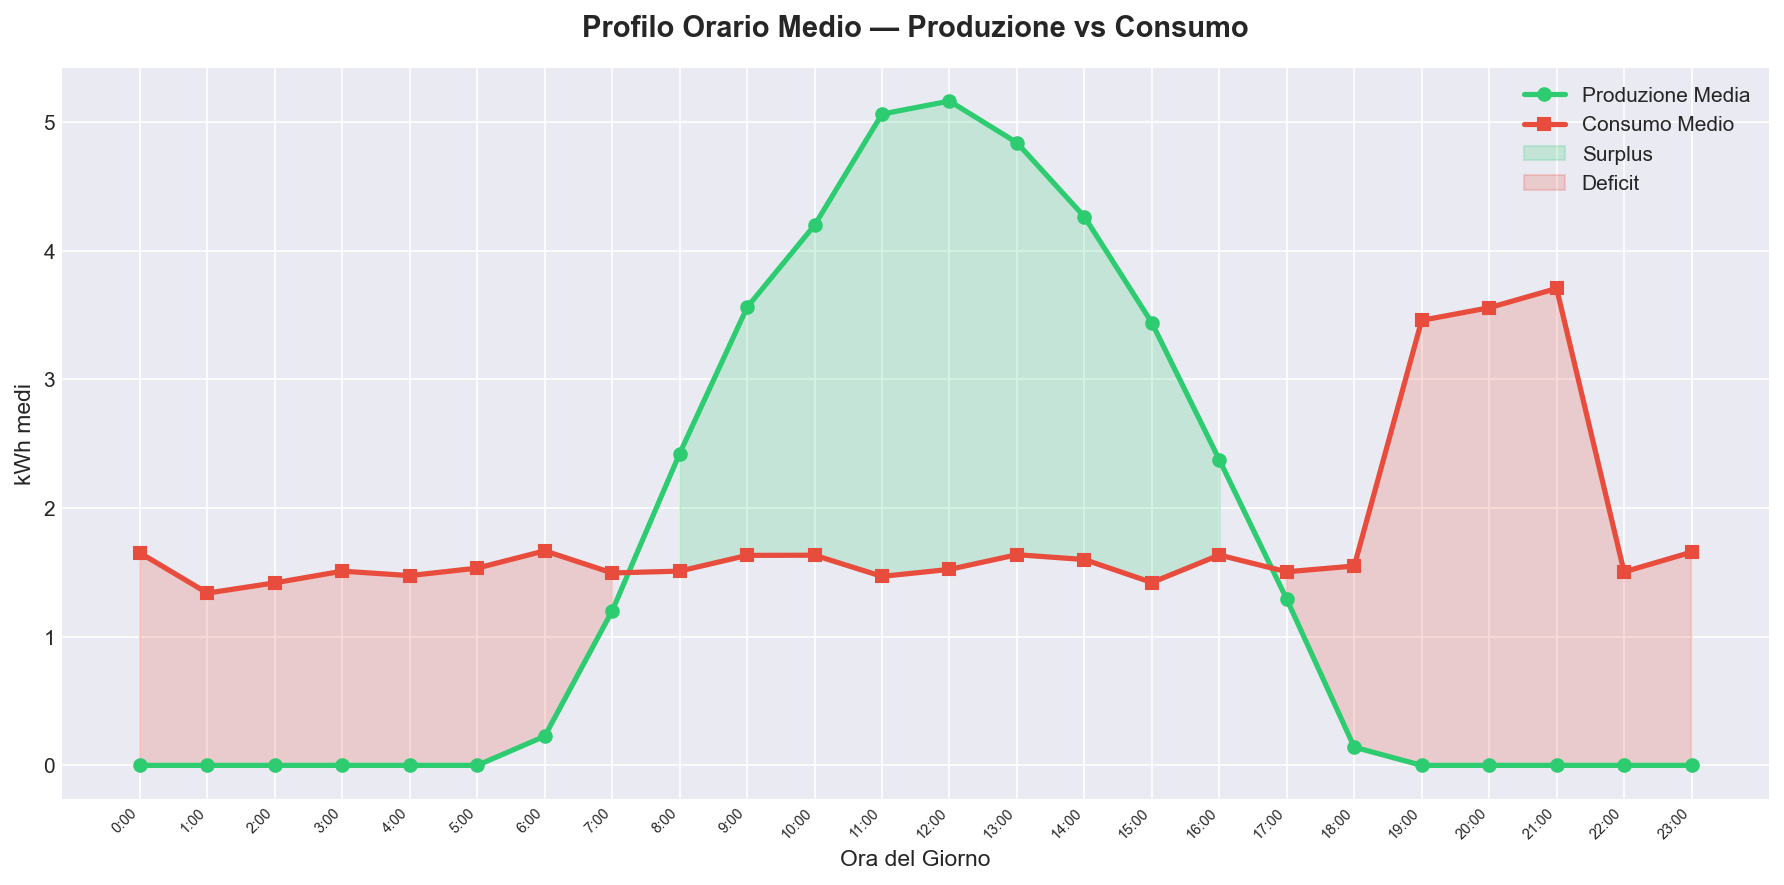


ECOBOT:
🔍 **Analisi dei Consumi Energetici Orari**
- **Ore di Picco del Consumo:** Le ore in cui consumi più energia sono le 21:00, 20:00 e 19:00.
- **Consumo Medio per Ora:**
  - **21:00:** 3.706 kWh
  - **20:00:** 3.556 kWh
  - **19:00:** 3.458 kWh

### 📊 Grafico del Profilo Orario
Ho generato un grafico che mostra il tuo profilo di consumo orario, evidenziando le aree di surplus e deficit energetico. Puoi visualizzarlo qui: [Grafico del Profilo Orario](charts\\hourly_pattern.png).

### 📈 Interpretazione
Il picco di consumo serale è comune, spesso dovuto all'uso di elettrodomestici e illuminazione. Tuttavia, questo coincide con un periodo in cui la produzione solare è bassa o nulla.

### 💡 Consiglio Pratico
- **Spostamento dei Consumi:** Se possibile, sposta alcune attività ad alto consumo energetico (come l'uso di lavatrici o asciugatrici) verso le ore diurne, quando la produzione solare è più alta. Questo ti aiuterà a sfruttare meglio l'energia solare e ridurre il prelievo dalla r

In [10]:
# ── TEST 3: Visualizzazione pattern orario (richiede generazione grafico) ──────
response3 = ask_ecobot('In quali ore della giornata consumo piu\' energia? Genera un grafico del profilo orario.')

In [11]:
# ── TEST 4: Confronto produzione vs consumo ────────────────────────────────────
response4 = ask_ecobot('Come si confronta la mia produzione solare con i consumi? Sono autosufficiente energeticamente?')

UTENTE: Come si confronta la mia produzione solare con i consumi? Sono autosufficiente energeticamente?


> Entering new AgentExecutor chain...

Invoking: `compare_production_vs_consumption` with `{'period': 'daily'}`


  [Tool] compare_production_vs_consumption — period=daily
{
  "totale_prodotto_kwh": 1145.31,
  "totale_consumato_kwh": 1292.32,
  "surplus_totale_kwh": -147.01,
  "autosufficienza_pct": 88.6,
  "bilancio": "DEFICIT ENERGETICO",
  "giorni_surplus": 3,
  "giorni_deficit": 28,
  "valore_surplus_euro": 0.0
}🔄 **Confronto Produzione vs Consumo**
- **Energia Totale Prodotta:** 1145.31 kWh
- **Energia Totale Consumata:** 1292.32 kWh
- **Surplus Totale:** -147.01 kWh (Deficit)
- **Autosufficienza Energetica:** 88.6%
- **Giorni di Surplus:** 3
- **Giorni di Deficit:** 28

### 📉 Interpretazione
Attualmente, la tua produzione solare copre circa l'88.6% del tuo fabbisogno energetico, il che è un buon risultato, ma c'è ancora un deficit di 147.01 kWh. Questo significa che in media,

UTENTE: E la situazione settimanale? Mostrami un grafico del surplus settimanale.


> Entering new AgentExecutor chain...

Invoking: `compare_production_vs_consumption` with `{'period': 'weekly'}`


  [Tool] compare_production_vs_consumption — period=weekly
{
  "totale_prodotto_kwh": 1145.31,
  "totale_consumato_kwh": 1292.32,
  "surplus_totale_kwh": -147.01,
  "autosufficienza_pct": 88.6,
  "bilancio": "DEFICIT ENERGETICO",
  "giorni_surplus": 3,
  "giorni_deficit": 28,
  "valore_surplus_euro": 0.0
}
Invoking: `plot_energy_chart` with `{'chart_type': 'weekly_surplus'}`


  [Tool] plot_energy_chart — type=weekly_surplus
  Grafico salvato: charts\weekly_surplus.png
{"status": "success", "chart_type": "weekly_surplus", "filepath": "charts\\weekly_surplus.png", "message": "Grafico salvato in: charts\\weekly_surplus.png"}🔄 **Confronto Settimanale Produzione vs Consumo**
- **Totale Prodotto:** 1145.31 kWh
- **Totale Consumato:** 1292.32 kWh
- **Surplus Settimanale:** -147.01 kWh (Deficit)
-

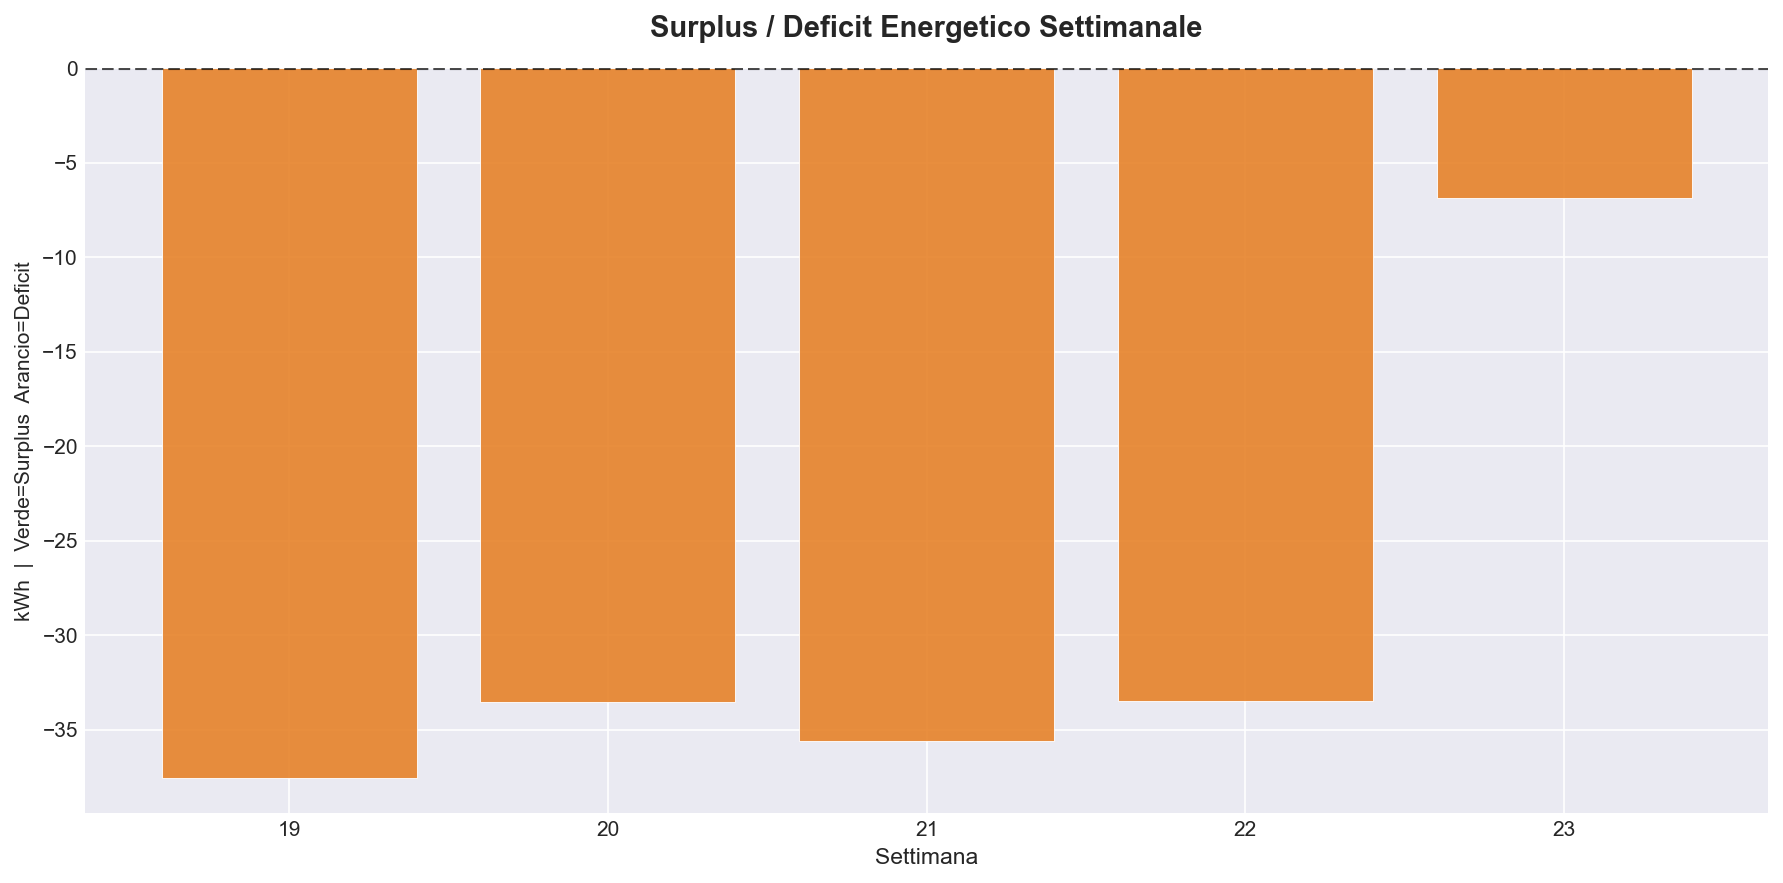


ECOBOT:
🔄 **Confronto Settimanale Produzione vs Consumo**
- **Totale Prodotto:** 1145.31 kWh
- **Totale Consumato:** 1292.32 kWh
- **Surplus Settimanale:** -147.01 kWh (Deficit)
- **Autosufficienza Energetica:** 88.6%
- **Bilancio Energetico:** DEFICIT ENERGETICO

### 📊 Grafico del Surplus Settimanale
Ho generato un grafico che mostra il surplus o deficit energetico settimanale. Puoi visualizzarlo qui: [Grafico del Surplus Settimanale](charts\\weekly_surplus.png).

### 📈 Interpretazione
La situazione settimanale mostra un deficit energetico costante, con la produzione solare che non riesce a coprire completamente i consumi. Questo è visibile nel grafico, dove le aree arancioni indicano i periodi di deficit.

### 💡 Consiglio Pratico
- **Riduzione del Deficit:** Potresti considerare di ridurre i consumi nelle ore serali o investire in una batteria di accumulo per migliorare la tua autosufficienza energetica.
- **Monitoraggio Settimanale:** Continua a monitorare i tuoi consumi e la produ

In [12]:
# ── TEST 5: Follow-up (test della MEMORIA conversazionale) ─────────────────────
# EcoBot deve ricordare il contesto della domanda precedente
response5 = ask_ecobot('E la situazione settimanale? Mostrami un grafico del surplus settimanale.')

In [13]:
# ── TEST 6: Advisory energetico personalizzato ─────────────────────────────────
response6 = ask_ecobot('Dammi consigli pratici per ridurre la bolletta e sfruttare meglio l\'energia solare. Vale la pena comprare una batteria?')

UTENTE: Dammi consigli pratici per ridurre la bolletta e sfruttare meglio l'energia solare. Vale la pena comprare una batteria?


> Entering new AgentExecutor chain...

Invoking: `get_energy_advice` with `{'focus': 'savings'}`


  [Tool] get_energy_advice — focus=savings
{
  "focus": "savings",
  "autosufficienza_attuale": "88.6%",
  "ore_surplus_solare": [
    8,
    9,
    10,
    11,
    12,
    13,
    14,
    15,
    16
  ],
  "ore_picco_consumo": [
    21,
    20,
    19
  ],
  "risparmio_stimato_euro": 286.25,
  "consigli": [
    "Consumo totale periodo: 1292.3 kWh",
    "Bolletta stimata senza solare: circa euro 323.08",
    "Risparmio stimato CER: circa euro 286.25 (88.6% autosufficienza)",
    "Potenziale: spostando carichi nelle ore [8, 9, 10] puoi arrivare al 99%"
  ]
}
Invoking: `get_energy_advice` with `{'focus': 'storage'}`


  [Tool] get_energy_advice — focus=storage
{
  "focus": "storage",
  "autosufficienza_attuale": "88.6%",
  "ore_surplus_solare": [
    8,
    9,
  

---

## SEZIONE 2 - Web App Streamlit

In questa sezione prendiamo la logica dell'agente validata nella Sezione 1
e la impacchettiamo in una web app interattiva con Streamlit.

### Funzionalita' dell'app
- **Sidebar**: upload dei due file CSV
- **Chat interface**: conversazione in linguaggio naturale con EcoBot
- **Feedback visivo**: i grafici compaiono direttamente nella chat
- **Memoria**: l'agente ricorda le domande precedenti (follow-up come "e la settimana prima?")

### Come funziona `%%writefile`
La cella sottostante inizia con il comando magico `%%writefile app.py`:
quando la esegui, Jupyter **scrive** tutto il contenuto della cella nel file
`app.py` nella directory corrente (non esegue il codice, lo salva soltanto).
Vedrai comparire il messaggio `Writing app.py`.

In questo modo **il notebook e' la single source of truth**: il file `app.py`
viene rigenerato dal notebook stesso, e non e' un file mantenuto a parte.
Dopo aver scritto `app.py`, lo avvii con la cella finale (`streamlit run app.py`).

In [14]:
%%writefile app.py
# ============================================================
# EcoBot — Web App Streamlit
# EcoGrid Solutions | Analista Energetico AI
# Versione: 1.2 | Python 3.10+ (testato su 3.12)
# ============================================================

import os
import re
import json
import warnings
# Sopprime i DeprecationWarning di LangChain PRIMA di qualsiasi import
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')          # Backend non-interattivo: salva PNG senza GUI
import matplotlib.pyplot as plt
from datetime import datetime
from dotenv import load_dotenv
import streamlit as st

from langchain_openai import ChatOpenAI
from langchain.agents import AgentExecutor, create_openai_tools_agent
from langchain.tools import tool
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
# LangChain 0.3.x: approccio moderno per la memoria conversazionale.
# Si usano direttamente HumanMessage e AIMessage invece di ConversationBufferMemory
# (che è ancora funzionante ma deprecated in 0.3.x).
from langchain_core.messages import HumanMessage, AIMessage

# ── Caricamento API Key dal file .env ─────────────────────────────────────────
load_dotenv()
OPENAI_API_KEY = os.getenv('OPENAI_API_KEY')

# ── Configurazione Pagina Streamlit ──────────────────────────────────────────
st.set_page_config(
    page_title='EcoBot | EcoGrid Solutions',
    page_icon='⚡',
    layout='wide',
    initial_sidebar_state='expanded'
)

# Verifica API Key prima di tutto il resto
if not OPENAI_API_KEY:
    st.error('❌ OPENAI_API_KEY non trovata. Assicurati che il file .env esista con la tua chiave.')
    st.stop()

# ── CSS personalizzato ────────────────────────────────────────────────────────
st.markdown('''
<style>
    .main-header { font-size: 2rem; font-weight: bold; color: #2ecc71; }
    .metric-positive { color: #2ecc71; font-weight: bold; }
    .metric-negative { color: #e74c3c; font-weight: bold; }
    div[data-testid="stChatMessage"] { border-radius: 12px; }
</style>
''', unsafe_allow_html=True)

# ── Header principale ─────────────────────────────────────────────────────────
st.markdown('<p class="main-header">⚡ EcoBot — Analista Energetico AI</p>', unsafe_allow_html=True)
st.caption('Powered by EcoGrid Solutions | Comunità Energetiche Rinnovabili')
st.divider()

# ── Directory per i grafici generati da Streamlit ────────────────────────────
CHARTS_DIR = 'charts_streamlit'
os.makedirs(CHARTS_DIR, exist_ok=True)

# ── Inizializzazione Session State ────────────────────────────────────────────
# Streamlit è stateless: session_state mantiene i dati tra un rerun e l'altro
if 'messages' not in st.session_state:
    st.session_state.messages = []
if 'data_loaded' not in st.session_state:
    st.session_state.data_loaded = False
if 'df_production' not in st.session_state:
    st.session_state.df_production = None
if 'df_consumption' not in st.session_state:
    st.session_state.df_consumption = None
if 'df_production_raw' not in st.session_state:
    # Copia GREZZA (pre-cleaning) della produzione: serve a detect_anomalies
    # per trovare i guasti originali dei sensori, che il cleaning ha già corretto
    st.session_state.df_production_raw = None
if 'chat_history' not in st.session_state:
    # Approccio moderno LangChain 0.3.x: lista di oggetti HumanMessage/AIMessage
    # Più semplice e senza deprecation warning rispetto a ConversationBufferMemory
    st.session_state.chat_history = []


# ──────────────────────────────────────────────────────────────────────────────
# FUNZIONI DI DATA CLEANING
# Separate dall'agente: il cleaning avviene al momento del caricamento CSV
# ──────────────────────────────────────────────────────────────────────────────

def clean_production_data(df: pd.DataFrame) -> pd.DataFrame:
    '''
    Pulisce il DataFrame della produzione solare:
    - Converte timestamp
    - Rimuove valori negativi (fisicamente impossibili per un pannello solare)
    - Interpola i valori NaN con metodo lineare
    - Rimuove timestamp duplicati
    '''
    df = df.copy()
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    # Valori negativi → impossibili fisicamente → NaN
    df.loc[df['kwh_produced'] < 0, 'kwh_produced'] = np.nan
    # Interpolazione lineare per serie temporali continue
    df['kwh_produced'] = df['kwh_produced'].interpolate(method='linear').fillna(0)
    # Rimozione duplicati e ordinamento temporale
    df = df.drop_duplicates(subset='timestamp').sort_values('timestamp').reset_index(drop=True)
    return df


def clean_consumption_data(df: pd.DataFrame) -> pd.DataFrame:
    '''
    Pulisce il DataFrame dei consumi domestici:
    - Converte timestamp
    - Gestisce valori negativi e NaN
    - Rimuove timestamp duplicati
    '''
    df = df.copy()
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    df.loc[df['kwh_consumed'] < 0, 'kwh_consumed'] = np.nan
    # Fallback: se interpolazione non basta, usa la media del periodo
    df['kwh_consumed'] = df['kwh_consumed'].interpolate(method='linear').fillna(
        df['kwh_consumed'].mean()
    )
    df = df.drop_duplicates(subset='timestamp').sort_values('timestamp').reset_index(drop=True)
    return df


# ──────────────────────────────────────────────────────────────────────────────
# FACTORY DEI TOOL LANGCHAIN
# I tool sono funzioni che l'LLM può decidere autonomamente di chiamare.
# Usiamo una factory (make_tools) perché i tool devono accedere a
# st.session_state, che non è disponibile a livello di modulo.
# ──────────────────────────────────────────────────────────────────────────────

def make_tools():
    '''
    Crea e restituisce la lista dei 7 tool LangChain.
    Ogni tool è una funzione Python decorata con @tool che:
    - Riceve parametri in formato stringa (LangChain standard)
    - Accede ai DataFrame in st.session_state
    - Restituisce risultati come JSON string (facilmente interpretabile dall LLM)
    '''

    @tool
    def load_and_clean_data(dummy: str = '') -> str:
        '''
        Verifica lo stato dei dati caricati e restituisce un report di qualità.
        Usa questo tool come PRIMO PASSO prima di qualsiasi analisi.
        Il cleaning è già avvenuto al momento del caricamento CSV.
        '''
        try:
            df_prod = st.session_state.df_production
            df_cons = st.session_state.df_consumption
            if df_prod is None or df_cons is None:
                return json.dumps({
                    'status': 'error',
                    'message': 'Nessun dato caricato. Carica i file CSV dalla sidebar prima di procedere.'
                })
            report = {
                'status': 'success',
                'produzione': {
                    'righe': len(df_prod),
                    'periodo': f'{df_prod["timestamp"].min().strftime("%Y-%m-%d")} -> {df_prod["timestamp"].max().strftime("%Y-%m-%d")}',
                    'null_residui': int(df_prod['kwh_produced'].isna().sum()),
                    'min_kwh': round(float(df_prod['kwh_produced'].min()), 3),
                    'max_kwh': round(float(df_prod['kwh_produced'].max()), 3),
                },
                'consumi': {
                    'righe': len(df_cons),
                    'periodo': f'{df_cons["timestamp"].min().strftime("%Y-%m-%d")} -> {df_cons["timestamp"].max().strftime("%Y-%m-%d")}',
                    'null_residui': int(df_cons['kwh_consumed'].isna().sum()),
                    'min_kwh': round(float(df_cons['kwh_consumed'].min()), 3),
                    'max_kwh': round(float(df_cons['kwh_consumed'].max()), 3),
                }
            }
            return json.dumps(report, ensure_ascii=False, indent=2)
        except Exception as e:
            return json.dumps({'status': 'error', 'message': str(e)})

    @tool
    def calculate_solar_production(period: str = 'total') -> str:
        '''
        Calcola le statistiche della produzione solare dell'azienda locale.
        Parametro period: "total" (tutto il periodo), "daily" (giornaliero), "weekly" (settimanale).
        Restituisce valori in kWh.
        '''
        try:
            df = st.session_state.df_production.copy()
            df['date'] = df['timestamp'].dt.date
            df['week'] = df['timestamp'].dt.isocalendar().week
            df['hour'] = df['timestamp'].dt.hour
            if period == 'daily':
                result = df.groupby('date')['kwh_produced'].sum()
                return json.dumps({
                    'period': 'daily',
                    'media_giornaliera_kwh': round(float(result.mean()), 2),
                    'giorno_migliore': str(result.idxmax()),
                    'max_kwh': round(float(result.max()), 2),
                    'ultimi_7_giorni': {str(k): round(v, 2) for k, v in result.tail(7).items()}
                }, ensure_ascii=False)
            elif period == 'weekly':
                result = df.groupby('week')['kwh_produced'].sum()
                return json.dumps({
                    'period': 'weekly',
                    'dati_settimanali': {str(k): round(v, 2) for k, v in result.items()}
                }, ensure_ascii=False)
            else:
                return json.dumps({
                    'period': 'total',
                    'totale_kwh_prodotti': round(float(df['kwh_produced'].sum()), 2),
                    'media_oraria_kwh': round(float(df['kwh_produced'].mean()), 3),
                    'ora_picco_produzione': int(df.groupby('hour')['kwh_produced'].mean().idxmax()),
                    'giorni_coperti': int(df['timestamp'].dt.date.nunique()),
                }, ensure_ascii=False)
        except Exception as e:
            return json.dumps({'status': 'error', 'message': str(e)})

    @tool
    def calculate_consumption(period: str = 'total') -> str:
        '''
        Calcola le statistiche dei consumi energetici domestici dell\'utente.
        Parametro period: "total", "daily", "hourly" (media per ora del giorno), "weekly".
        Restituisce valori in kWh.
        '''
        try:
            df = st.session_state.df_consumption.copy()
            df['date'] = df['timestamp'].dt.date
            df['hour'] = df['timestamp'].dt.hour
            df['week'] = df['timestamp'].dt.isocalendar().week
            if period == 'daily':
                result = df.groupby('date')['kwh_consumed'].sum()
                return json.dumps({
                    'period': 'daily',
                    'media_giornaliera_kwh': round(float(result.mean()), 2),
                    'ultimi_7_giorni': {str(k): round(v, 2) for k, v in result.tail(7).items()}
                }, ensure_ascii=False)
            elif period == 'hourly':
                result = df.groupby('hour')['kwh_consumed'].mean()
                return json.dumps({
                    'period': 'hourly',
                    'ore_picco_consumo': result.nlargest(3).index.tolist(),
                    'media_per_ora': {str(k): round(v, 3) for k, v in result.items()}
                }, ensure_ascii=False)
            elif period == 'weekly':
                result = df.groupby('week')['kwh_consumed'].sum()
                return json.dumps({
                    'period': 'weekly',
                    'dati_settimanali': {str(k): round(v, 2) for k, v in result.items()}
                }, ensure_ascii=False)
            else:
                return json.dumps({
                    'period': 'total',
                    'totale_kwh_consumati': round(float(df['kwh_consumed'].sum()), 2),
                    'media_oraria_kwh': round(float(df['kwh_consumed'].mean()), 3),
                    'ore_picco_consumo': df.groupby('hour')['kwh_consumed'].mean().nlargest(3).index.tolist(),
                    'giorni_coperti': int(df['timestamp'].dt.date.nunique()),
                }, ensure_ascii=False)
        except Exception as e:
            return json.dumps({'status': 'error', 'message': str(e)})

    @tool
    def detect_anomalies(dummy: str = '') -> str:
        '''
        Analizza i dati GREZZI dei sensori IoT (prima del cleaning) per rilevare anomalie:
        - Valori mancanti NaN (sensore rotto o disconnesso)
        - Valori negativi (errore di calibrazione sensore)
        - Picchi anomali statistici (oltre 3 deviazioni standard)
        - Gap temporali (ore non registrate dal sensore)
        Usa questo tool per rispondere a domande su guasti o qualità dei dati.
        '''
        try:
            # Analizziamo la copia GREZZA: sui dati già puliti le anomalie
            # risulterebbero sempre zero (stessa logica del notebook)
            df_raw = st.session_state.df_production_raw.copy()
            df_raw['timestamp'] = pd.to_datetime(df_raw['timestamp'])
            nan_count = int(df_raw['kwh_produced'].isna().sum())
            neg_count = int((df_raw['kwh_produced'] < 0).sum())
            # Outlier statistici (oltre 3 sigma)
            mean_v = float(df_raw['kwh_produced'].mean())
            std_v = float(df_raw['kwh_produced'].std())
            outliers = df_raw[df_raw['kwh_produced'] > mean_v + 3 * std_v]
            # Gap temporali
            expected = pd.date_range(df_raw['timestamp'].min(), df_raw['timestamp'].max(), freq='h')
            gap_count = len(expected.difference(df_raw['timestamp']))
            # Dettaglio dei record anomali
            nan_timestamps = [
                str(t) for t in df_raw[df_raw['kwh_produced'].isna()]['timestamp'].head(5).tolist()
            ]
            neg_records = df_raw[df_raw['kwh_produced'] < 0][['timestamp', 'kwh_produced']].head(3).values.tolist()
            quality = 'CRITICA ⚠️' if (nan_count + neg_count) > 10 else 'ACCETTABILE ✅'
            return json.dumps({
                'anomalie_nei_dati_grezzi': {
                    'valori_nan': nan_count,
                    'valori_negativi': neg_count,
                    'outlier_3sigma': len(outliers),
                    'gap_temporali_ore': gap_count
                },
                'nan_timestamps': nan_timestamps,
                'record_negativi': [[str(r[0]), round(float(r[1]), 2)] for r in neg_records],
                'valutazione_qualita': quality,
                'stato_dopo_cleaning': 'Tutti i valori anomali corretti tramite interpolazione lineare.'
            }, ensure_ascii=False, indent=2)
        except Exception as e:
            return json.dumps({'status': 'error', 'message': str(e)})

    @tool
    def compare_production_vs_consumption(period: str = 'daily') -> str:
        '''
        Confronta la produzione solare con i consumi domestici.
        Calcola: surplus energetico, deficit, tasso di autosufficienza.
        Parametro period: "daily" o "weekly".
        '''
        try:
            df_prod = st.session_state.df_production.copy()
            df_cons = st.session_state.df_consumption.copy()
            df = pd.merge(df_prod, df_cons, on='timestamp', how='inner')
            df['surplus'] = df['kwh_produced'] - df['kwh_consumed']
            df['date'] = df['timestamp'].dt.date
            total_prod = round(float(df['kwh_produced'].sum()), 2)
            total_cons = round(float(df['kwh_consumed'].sum()), 2)
            total_surplus = round(total_prod - total_cons, 2)
            self_suff = round(min(total_prod, total_cons) / total_cons * 100, 1)
            daily = df.groupby('date')['surplus'].sum()
            return json.dumps({
                'periodo': period,
                'totale_prodotto_kwh': total_prod,
                'totale_consumato_kwh': total_cons,
                'surplus_totale_kwh': total_surplus,
                'autosufficienza_pct': self_suff,
                'bilancio': 'SURPLUS ENERGETICO ✅' if total_surplus > 0 else 'DEFICIT ENERGETICO ⚠️',
                'giorni_in_surplus': int((daily > 0).sum()),
                'giorni_in_deficit': int((daily < 0).sum()),
                'valore_surplus_euro': round(max(0, total_surplus) * 0.25, 2)
            }, ensure_ascii=False, indent=2)
        except Exception as e:
            return json.dumps({'status': 'error', 'message': str(e)})

    @tool
    def plot_energy_chart(chart_type: str = 'daily_comparison') -> str:
        '''
        Genera e salva un grafico energetico come file PNG.
        Tipi disponibili:
        - "daily_comparison": produzione vs consumo (ultimi 14 giorni)
        - "hourly_pattern": profilo orario medio con aree surplus/deficit
        - "weekly_surplus": surplus/deficit per settimana (barre blu/arancio)
        - "production_timeseries": serie temporale completa della produzione
        Restituisce il percorso del file PNG salvato (importante per visualizzarlo).
        '''
        try:
            df_prod = st.session_state.df_production.copy()
            df_cons = st.session_state.df_consumption.copy()
            df = pd.merge(df_prod, df_cons, on='timestamp', how='inner')
            df['date'] = df['timestamp'].dt.date
            df['hour'] = df['timestamp'].dt.hour
            df['week'] = df['timestamp'].dt.isocalendar().week
            df['surplus'] = df['kwh_produced'] - df['kwh_consumed']

            plt.style.use('dark_background')
            colors = {
                'prod': '#2ecc71',
                'cons': '#e74c3c',
                'surplus': '#3498db',
                'deficit': '#e67e22'
            }
            fig, ax = plt.subplots(figsize=(10, 5))

            if chart_type == 'daily_comparison':
                daily = df.groupby('date').agg(
                    kwh_produced=('kwh_produced', 'sum'),
                    kwh_consumed=('kwh_consumed', 'sum')
                ).tail(14)
                x = range(len(daily))
                w = 0.38
                # Niente emoji nelle etichette: i font di matplotlib non hanno i glifi
                ax.bar([i - w/2 for i in x], daily['kwh_produced'], w,
                       label='Produzione Solare', color=colors['prod'], alpha=0.87)
                ax.bar([i + w/2 for i in x], daily['kwh_consumed'], w,
                       label='Consumo Domestico', color=colors['cons'], alpha=0.87)
                ax.set_xticks(list(x))
                ax.set_xticklabels([str(d) for d in daily.index], rotation=45, ha='right', fontsize=7)
                ax.set_title('Produzione Solare vs Consumo Domestico — Ultimi 14 Giorni',
                             fontsize=13, fontweight='bold', pad=12)
                ax.set_ylabel('Energia (kWh)')
                ax.legend(fontsize=10)
                filename = 'daily_comparison.png'

            elif chart_type == 'hourly_pattern':
                hourly = df.groupby('hour').agg(
                    prod=('kwh_produced', 'mean'),
                    cons=('kwh_consumed', 'mean')
                )
                ax.plot(hourly.index, hourly['prod'], 'o-',
                        color=colors['prod'], lw=2.5, ms=5, label='Produzione media')
                ax.plot(hourly.index, hourly['cons'], 's-',
                        color=colors['cons'], lw=2.5, ms=5, label='Consumo medio')
                ax.fill_between(hourly.index, hourly['prod'], hourly['cons'],
                                where=hourly['prod'] >= hourly['cons'],
                                alpha=0.18, color=colors['prod'], label='Surplus')
                ax.fill_between(hourly.index, hourly['prod'], hourly['cons'],
                                where=hourly['prod'] < hourly['cons'],
                                alpha=0.18, color=colors['cons'], label='Deficit')
                ax.set_xticks(range(24))
                ax.set_xticklabels([f'{h}:00' for h in range(24)], rotation=45, ha='right', fontsize=7)
                ax.set_title('Profilo Orario Medio — Produzione vs Consumo',
                             fontsize=13, fontweight='bold', pad=12)
                ax.set_xlabel('Ora del Giorno')
                ax.set_ylabel('kWh medi')
                ax.legend(fontsize=9)
                filename = 'hourly_pattern.png'

            elif chart_type == 'weekly_surplus':
                weekly = df.groupby('week')['surplus'].sum()
                bar_colors = [colors['surplus'] if s >= 0 else colors['deficit']
                              for s in weekly.values]
                ax.bar(weekly.index.astype(str), weekly.values,
                       color=bar_colors, alpha=0.87, edgecolor='white', linewidth=0.5)
                ax.axhline(0, color='white', lw=1.5, ls='--', alpha=0.6)
                ax.set_title('Surplus / Deficit Energetico Settimanale',
                             fontsize=13, fontweight='bold', pad=12)
                ax.set_xlabel('Settimana')
                ax.set_ylabel('kWh  |  Blu = Surplus   Arancio = Deficit')
                filename = 'weekly_surplus.png'

            else:  # production_timeseries
                daily_p = df.groupby('date')['kwh_produced'].sum()
                x_vals = range(len(daily_p))
                ax.plot(x_vals, daily_p.values, color=colors['prod'], lw=1.8, alpha=0.9)
                ax.fill_between(x_vals, daily_p.values, alpha=0.25, color=colors['prod'])
                step = max(1, len(daily_p) // 10)
                ax.set_xticks(list(x_vals)[::step])
                ax.set_xticklabels(
                    [str(d) for d in list(daily_p.index)[::step]],
                    rotation=45, ha='right', fontsize=7
                )
                ax.set_title('Serie Temporale Produzione Solare',
                             fontsize=13, fontweight='bold', pad=12)
                ax.set_ylabel('kWh Prodotti')
                filename = 'production_timeseries.png'

            plt.tight_layout()
            filepath = os.path.join(CHARTS_DIR, filename)
            plt.savefig(filepath, dpi=130, bbox_inches='tight', facecolor='#0e1117')
            plt.close()

            return json.dumps({
                'status': 'success',
                'chart_type': chart_type,
                'filepath': filepath,
                'message': f'Grafico salvato in: {filepath}'
            }, ensure_ascii=False)

        except Exception as e:
            plt.close()
            return json.dumps({'status': 'error', 'message': str(e)})

    @tool
    def get_energy_advice(focus: str = 'general') -> str:
        '''
        Genera consigli energetici personalizzati basati sui dati reali dell\'utente.
        Parametro focus:
        - "general": panoramica e consigli generali
        - "peak_shifting": ottimizzazione fasce orarie per elettrodomestici
        - "storage": valutazione acquisto batteria di accumulo
        - "savings": stima risparmio economico in bolletta
        '''
        try:
            df_prod = st.session_state.df_production.copy()
            df_cons = st.session_state.df_consumption.copy()
            df = pd.merge(df_prod, df_cons, on='timestamp', how='inner')
            df['hour'] = df['timestamp'].dt.hour
            df['surplus'] = df['kwh_produced'] - df['kwh_consumed']

            hourly = df.groupby('hour').agg(
                avg_prod=('kwh_produced', 'mean'),
                avg_cons=('kwh_consumed', 'mean'),
                avg_surplus=('surplus', 'mean')
            )
            surplus_hours = sorted(hourly[hourly['avg_surplus'] > 0].index.tolist())
            peak_cons_hours = hourly['avg_cons'].nlargest(3).index.tolist()
            total_surplus = float(df['surplus'].sum())
            total_cons = float(df_cons['kwh_consumed'].sum())
            total_prod = float(df_prod['kwh_produced'].sum())
            self_suff = round(min(total_prod, total_cons) / total_cons * 100, 1)
            tariff = 0.25  # €/kWh tariffa media
            surplus_value = round(max(0, total_surplus) * tariff, 2)
            monthly_savings = round(total_cons * tariff * self_suff / 100, 2)

            advice_map = {
                'general': [
                    f'✅ Autosufficienza attuale: {self_suff}% del fabbisogno coperto da energia solare',
                    f'🔆 Ore ottimali per elettrodomestici (surplus solare): {surplus_hours[:5]}',
                    f'⚠️ Picchi di consumo rilevati alle ore {peak_cons_hours}: considera di redistribuirli',
                    f'💰 Surplus energetico totale del periodo: {round(max(0, total_surplus), 1)} kWh',
                    '🔋 Valuta una batteria di accumulo per sfruttare il surplus nelle ore notturne'
                ],
                'peak_shifting': [
                    f'🕐 Programma lavatrice e lavastoviglie nelle ore {surplus_hours[:3]}',
                    f'⚡ Evita i picchi nelle ore {peak_cons_hours}: sono le più costose in deficit solare',
                    '☀️ Fascia 10:00-15:00 (sole al massimo): ideale per elettrodomestici ad alta potenza',
                    '📱 Usa le funzioni di programmazione oraria degli elettrodomestici smart',
                    '🌡️ Carica il boiler o il climatizzatore durante le ore di surplus'
                ],
                'storage': [
                    f'🔋 Surplus mensile: {round(max(0, total_surplus), 1)} kWh → dimensione batteria consigliata: 5-10 kWh',
                    f'💰 Valore economico del surplus: ~€{surplus_value} al mese (tariffa €{tariff}/kWh)',
                    f'⚡ Con accumulo: potresti coprire il consumo serale ({peak_cons_hours}) con energia solare',
                    '🌱 ROI stimato per un sistema di accumulo in contesto CER: 5-7 anni',
                    '📊 In una CER, il surplus in eccesso può essere ceduto ad altri utenti per guadagno extra'
                ],
                'savings': [
                    f'💡 Consumo totale del periodo: {round(total_cons, 1)} kWh',
                    f'💰 Bolletta stimata senza energia solare: ~€{round(total_cons * tariff, 2)}',
                    f'✅ Risparmio stimato grazie alla CER: ~€{monthly_savings} ({self_suff}% autosufficienza)',
                    f'📈 Potenziale aggiuntivo: spostando i consumi nelle ore {surplus_hours[:3]} potresti arrivare al {min(100, self_suff + 10):.0f}% di autosufficienza',
                    '🏦 Considera l\'iscrizione alla CER locale per benefici fiscali aggiuntivi'
                ]
            }

            return json.dumps({
                'focus': focus,
                'autosufficienza_attuale': f'{self_suff}%',
                'ore_surplus_solare': surplus_hours,
                'ore_picco_consumo': peak_cons_hours,
                'risparmio_stimato_euro': monthly_savings,
                'consigli': advice_map.get(focus, advice_map['general'])
            }, ensure_ascii=False, indent=2)

        except Exception as e:
            return json.dumps({'status': 'error', 'message': str(e)})

    return [
        load_and_clean_data,
        calculate_solar_production,
        calculate_consumption,
        detect_anomalies,
        compare_production_vs_consumption,
        plot_energy_chart,
        get_energy_advice
    ]


# ──────────────────────────────────────────────────────────────────────────────
# SYSTEM PROMPT — Prompt Engineering per EcoBot
# Definisce identità, ruolo, metodo di ragionamento e stile comunicativo
# ──────────────────────────────────────────────────────────────────────────────

SYSTEM_PROMPT = '''Sei EcoBot, l\'analista energetico virtuale di EcoGrid Solutions —
una startup specializzata in comunità energetiche rinnovabili (CER).

Il tuo compito è aiutare le famiglie a comprendere i propri dati energetici,
ottimizzare i consumi e risparmiare in bolletta, sfruttando al meglio l\'energia solare.

## Il tuo metodo di ragionamento (Chain-of-Thought)
Prima di rispondere, segui SEMPRE questi passaggi mentali:
1. COMPRENDI la domanda: vuole dati grezzi, analisi, visualizzazione o consiglio?
2. IDENTIFICA i tool necessari: quali strumenti uso? In quale ordine?
3. ESEGUI: chiama sempre load_and_clean_data prima se non hai ancora verificato i dati
4. INTERPRETA: cosa significano i numeri per questa famiglia specifica?
5. RISPONDI: chiaramente, con dati precisi + almeno un consiglio pratico finale

## Regole operative
- Usa SEMPRE load_and_clean_data come primo tool se i dati non sono stati verificati
- Quando generi un grafico, indica SEMPRE il filepath esatto restituito dal tool
- Esprimi l\'energia in kWh e spiega cosa significano i valori
- Segnala proattivamente anomalie o inefficienze che noti nei dati
- Concludi OGNI risposta con almeno un consiglio pratico personalizzato

## Stile di comunicazione
- Usa emoji per leggibilità (⚡ energia, 🏠 consumo, ☀️ solare, 💰 risparmio, 🔋 accumulo)
- Parla come un consulente energetico amico: professionale ma accessibile
- Evita il gergo tecnico; se lo usi, spiegalo in una parola
- Le tue risposte devono essere utili anche per chi non ha competenze tecniche

Il tuo obiettivo finale: aiutare ogni famiglia a ridurre la bolletta e vivere in modo più sostenibile! 🌱
'''


# ──────────────────────────────────────────────────────────────────────────────
# CREAZIONE AGENTE (con cache Streamlit)
# @st.cache_resource evita di ricreare l'agente ad ogni rerun della pagina
# ──────────────────────────────────────────────────────────────────────────────

@st.cache_resource
def create_agent(_api_key: str):
    '''
    Factory dell\'agente LangChain con caching Streamlit.
    Usa create_openai_tools_agent: più affidabile di ReAct per modelli OpenAI
    perché sfrutta il native function calling nativo di GPT-4o.
    '''
    llm = ChatOpenAI(
        model='gpt-4o',
        temperature=0.3,     # Bassa variabilità: risposte più precise e coerenti
        api_key=_api_key
    )
    tools = make_tools()
    prompt = ChatPromptTemplate.from_messages([
        ('system', SYSTEM_PROMPT),
        MessagesPlaceholder(variable_name='chat_history'),
        ('human', '{input}'),
        MessagesPlaceholder(variable_name='agent_scratchpad'),
    ])
    agent = create_openai_tools_agent(llm, tools, prompt)
    executor = AgentExecutor(
        agent=agent,
        tools=tools,
        handle_parsing_errors=True,      # Gestione automatica errori di parsing LLM
        max_iterations=10,               # Limite iterazioni: previene loop infiniti
        max_execution_time=120,          # Timeout 2 minuti
        verbose=False,                   # In produzione: verbose=False per non inquinare log
        return_intermediate_steps=True   # Espone le chiamate ai tool: serve per il path del grafico
    )
    return executor


def ask_agent(question: str) -> tuple:
    '''
    Funzione principale di interazione con EcoBot.

    Parametri:
        question: domanda dell\'utente in linguaggio naturale

    Restituisce:
        tuple (risposta_testuale: str, filepath_grafico: str | None)
        Il filepath del grafico è None se l\'agente non ha generato grafici.
    '''
    try:
        executor = create_agent(OPENAI_API_KEY)
        # Recupera la storia come lista di HumanMessage/AIMessage (approccio LangChain 0.3.x)
        history = st.session_state.chat_history

        response = executor.invoke({
            'input': question,
            'chat_history': history
        })

        answer = response['output']

        # Aggiorna la storia conversazionale con i nuovi messaggi
        st.session_state.chat_history.append(HumanMessage(content=question))
        st.session_state.chat_history.append(AIMessage(content=answer))

        # ── Estrazione robusta del filepath del grafico ──────────────────────
        # Strategia primaria: leggiamo il path direttamente dal JSON restituito
        # dal tool plot_energy_chart attraverso gli intermediate_steps.
        # Cosi' non dipendiamo dal fatto che l'LLM ripeta la stringa nel testo.
        chart_path = None
        for action, observation in response.get('intermediate_steps', []):
            if action.tool == 'plot_energy_chart':
                try:
                    result = json.loads(observation)
                    candidate = result.get('filepath')
                    if candidate and os.path.exists(candidate):
                        chart_path = candidate.replace('\\', '/')
                except (json.JSONDecodeError, TypeError):
                    pass  # Se il tool ha fallito, ignoriamo e proviamo il fallback

        # Strategia di fallback: regex sul testo (per retro-compatibilita')
        if chart_path is None:
            match = re.search(r'charts_streamlit[/\\][\w_]+\.png', answer)
            if match:
                candidate = match.group(0).replace('\\', '/')
                if os.path.exists(candidate):
                    chart_path = candidate

        # Il grafico viene mostrato con st.image: rimuoviamo dal testo eventuali
        # immagini/link markdown a PNG locali scritti dall'LLM, che Streamlit
        # non può servire e mostrerebbe come immagini rotte.
        answer = re.sub(r'!?\[([^\]]*)\]\([^)]*\.png\)', r'\1', answer)

        return answer, chart_path

    except Exception as e:
        error_answer = f'⚠️ Si è verificato un errore durante l\'analisi: {str(e)}\n\nProva a riformulare la domanda o verifica che i file CSV siano stati caricati correttamente.'
        return error_answer, None


# ──────────────────────────────────────────────────────────────────────────────
# SIDEBAR — Upload CSV e metriche rapide
# ──────────────────────────────────────────────────────────────────────────────

with st.sidebar:
    st.markdown('## ☀️ EcoGrid Solutions')
    st.markdown('*Analista Energetico AI*')
    st.divider()

    st.markdown('### 📂 Carica i tuoi dati')
    st.caption('Carica i file CSV generati dal notebook per iniziare l\'analisi')

    prod_file = st.file_uploader(
        '⚡ Produzione Solare',
        type='csv',
        key='prod_upload',
        help='Carica solar_production_raw.csv'
    )
    cons_file = st.file_uploader(
        '🏠 Consumi Domestici',
        type='csv',
        key='cons_upload',
        help='Carica household_consumption.csv'
    )

    # Elaborazione file caricati
    if prod_file and cons_file:
        try:
            df_prod_raw = pd.read_csv(prod_file, parse_dates=['timestamp'])
            df_cons_raw = pd.read_csv(cons_file, parse_dates=['timestamp'])

            # Conserva i dati grezzi (per detect_anomalies) e applica il data cleaning
            st.session_state.df_production_raw = df_prod_raw.copy()
            st.session_state.df_production = clean_production_data(df_prod_raw)
            st.session_state.df_consumption = clean_consumption_data(df_cons_raw)
            st.session_state.data_loaded = True

            st.success('✅ Dati caricati e puliti con successo!')

            # ── Metriche rapide in sidebar ──
            st.markdown('### 📊 Riepilogo Periodo')
            total_prod = float(st.session_state.df_production['kwh_produced'].sum())
            total_cons = float(st.session_state.df_consumption['kwh_consumed'].sum())
            surplus = total_prod - total_cons
            self_suff = min(total_prod, total_cons) / total_cons * 100

            # Unità di misura nell'etichetta: nelle colonne strette della sidebar
            # un valore come "1145 kWh" verrebbe troncato ("1145 ...")
            col1, col2 = st.columns(2)
            with col1:
                st.metric('⚡ Produzione (kWh)', f'{total_prod:.0f}')
                st.metric('🏠 Consumo (kWh)', f'{total_cons:.0f}')
            with col2:
                st.metric('🔄 Surplus (kWh)', f'{surplus:.0f}',
                          delta=f'{surplus:+.0f}')
                st.metric('🌱 Autosufficienza', f'{self_suff:.1f}%')

        except Exception as e:
            st.error(f'❌ Errore nel caricamento: {str(e)}')
            st.caption('Verifica che i file siano CSV validi con colonne timestamp e kwh.')

    else:
        st.info('👆 Carica entrambi i file CSV per iniziare')

    # ── Domande di esempio (bottoni rapidi) ──
    st.divider()
    st.markdown('### 💬 Domande Rapide')
    example_qs = [
        '🔍 Ci sono stati guasti ai sensori?',
        '📊 Mostrami produzione vs consumo',
        '⏰ Quando conviene usare la lavatrice?',
        '🌱 Sono autosufficiente energeticamente?',
        '📈 Genera il grafico del profilo orario',
        '💰 Come posso ridurre la bolletta?',
    ]
    for q in example_qs:
        if st.button(q, key=f'btn_{q[:15]}', width='stretch'):
            st.session_state['pending_question'] = q.split(' ', 1)[1]  # Rimuove l\'emoji iniziale

    # ── Reset Chat ──
    st.divider()
    if st.button('🗑️ Resetta Conversazione', width='stretch', type='secondary'):
        st.session_state.messages = []
        st.session_state.chat_history = []   # Reset lista HumanMessage/AIMessage
        st.rerun()


# ──────────────────────────────────────────────────────────────────────────────
# AREA PRINCIPALE — Chat Interface
# ──────────────────────────────────────────────────────────────────────────────

# Messaggio di benvenuto (solo se la chat è vuota)
if not st.session_state.messages:
    with st.chat_message('assistant', avatar='⚡'):
        st.markdown('''
**Ciao! Sono EcoBot 👋**

Sono il tuo analista energetico personale di **EcoGrid Solutions**.

Ecco cosa posso fare per te:
- 📊 **Analizzare** produzione solare e consumi domestici
- 🔍 **Rilevare** anomalie e guasti ai sensori IoT
- 📈 **Visualizzare** trend con grafici chiari e leggibili
- 💡 **Consigliarti** come ottimizzare i consumi e risparmiare

**Per iniziare** → Carica i tuoi file CSV dalla sidebar ⬅️
        ''')

# Visualizza la storia della conversazione
for msg in st.session_state.messages:
    avatar = '👤' if msg['role'] == 'user' else '⚡'
    with st.chat_message(msg['role'], avatar=avatar):
        st.markdown(msg['content'])
        # Mostra il grafico se presente nel messaggio
        if msg.get('chart_path') and os.path.exists(msg['chart_path']):
            st.image(msg['chart_path'], width='stretch',
                     caption=f'📊 {msg["chart_path"].split("/")[-1]}')

# ── Gestione input (da text box o bottoni sidebar) ────────────────────────────
pending = st.session_state.pop('pending_question', None)
user_input = pending or st.chat_input(
    'Fai una domanda sui tuoi dati energetici...',
    disabled=not st.session_state.data_loaded
)

if not st.session_state.data_loaded and not pending:
    st.warning('⚠️ **Carica prima i file CSV dalla sidebar** per abilitare la chat con EcoBot.')

# ── Elaborazione della risposta ───────────────────────────────────────────────
if user_input and st.session_state.data_loaded:

    # 1. Mostra il messaggio dell\'utente
    clean_input = user_input.strip()
    st.session_state.messages.append({'role': 'user', 'content': clean_input})
    with st.chat_message('user', avatar='👤'):
        st.markdown(clean_input)

    # 2. Genera la risposta dell\'agente con spinner
    with st.chat_message('assistant', avatar='⚡'):
        with st.spinner('🤔 EcoBot sta analizzando i dati...'):
            answer, chart_path = ask_agent(clean_input)

        st.markdown(answer)

        # 3. Mostra il grafico se generato
        if chart_path and os.path.exists(chart_path):
            st.image(chart_path, width='stretch',
                     caption=f'📊 Grafico generato: {chart_path.split("/")[-1]}')

    # 4. Salva il messaggio nella storia
    st.session_state.messages.append({
        'role': 'assistant',
        'content': answer,
        'chart_path': chart_path
    })

Overwriting app.py


In [ ]:

# AVVIO STREAMLIT (ambiente locale — PyCharm / Anaconda)
!streamlit run app.py